## Importing libraries

In [3]:
import numpy as np
import pandas as pd
import os
import re
import shutil
import time
import tensorflow as tf
from tensorboard.plugins import projector
from time import time
from gensim.models import Word2Vec
from tqdm import tqdm
from wordcloud import WordCloud, STOPWORDS
import seaborn as sns
sns.set_style("darkgrid")
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
%matplotlib inline
%load_ext tensorboard

import logging  # Setting up the loggings to monitor gensim
logging.basicConfig(format="%(levelname)s - %(asctime)s: %(message)s", datefmt= '%H:%M:%S', level=logging.INFO)

tqdm.pandas()

## Loading the data


In [4]:
wiki = '/content/drive/MyDrive/Colab Notebooks/extra assignment/wikitext-2-v1.zip'
data_dir = '/content/drive/MyDrive/Colab Notebooks/extra assignment/data_dir'

In [5]:
shutil.unpack_archive(wiki, data_dir)

In [6]:
wikitext_2 = '/content/drive/MyDrive/Colab Notebooks/extra assignment/data_dir/wikitext-2'

In [7]:
os.listdir(wikitext_2)

['wiki.test.tokens', 'wiki.valid.tokens', 'wiki.train.tokens']

In [8]:
f = open('/content/drive/MyDrive/Colab Notebooks/extra assignment/data_dir/wikitext-2/wiki.train.tokens', "rt")
text = f.readlines()
print(text)

IOPub data rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_data_rate_limit`.

Current values:
NotebookApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
NotebookApp.rate_limit_window=3.0 (secs)



## Data preprocessing

In [9]:
def convertToList(text):
    res = []
    for i in range(0,len(text)):

        lis = list(text[i].split(' '))
        res.append(lis)
    return res

text = convertToList(text)

In [10]:
text[1]

['', '=', 'Valkyria', 'Chronicles', 'III', '=', '\n']

In [11]:
def preprocessing(text):
    processed_text = []
    for tokens in tqdm(text):
        # remove other non-alphabets symbols with space (i.e. keep only alphabets and whitespaces).
        processed = re.sub('[^a-zA-Z ]', '', tokens)
        words = processed.split()
        # keep words that have length of more than 1 (e.g. gb, bb), remove those with length 1.
        processed_text.append(' '.join([word for word in words if len(word) > 1]))
    return processed_text

In [12]:
text_string=''

for i in text:
    for j in i:
        text_string += j

## WordCloud

In [13]:
def plot_cloud(wordcloud):
    plt.figure(figsize=(40, 30))
    # Display image
    plt.imshow(wordcloud) 
    # No axis details
    plt.axis("off");

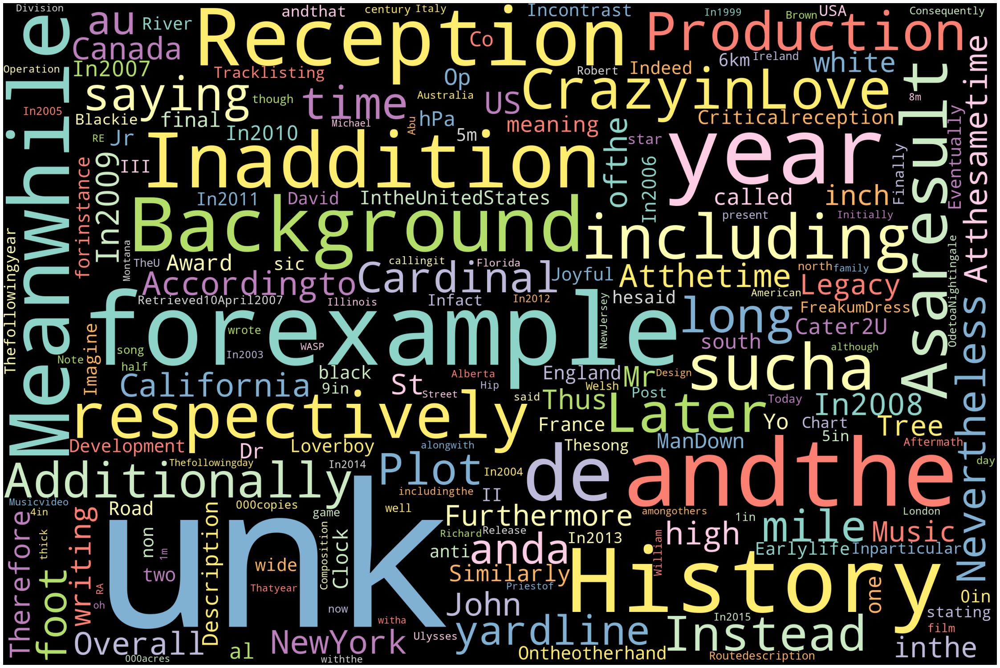

In [14]:
wordcloud = WordCloud(width = 3000, 
                      height = 2000, 
                      random_state=1, 
                      background_color='black', 
                      colormap='Set3', 
                      collocations=False, 
                      stopwords = STOPWORDS).generate(text_string)
plot_cloud(wordcloud)

In [15]:
wordcloud.to_file("/content/drive/MyDrive/Colab Notebooks/extra assignment/wordcloud.png")

## Creating our custom word embedding

In [16]:
w2v_model = Word2Vec(min_count=20,
                     window=2,
                     size=300,
                     sample=6e-5, 
                     alpha=0.03, 
                     min_alpha=0.0007, 
                     negative=20,
                     workers=4-1)

In [17]:
# Building the Vocabulary Table:

t = time()

w2v_model.build_vocab(text, progress_per=10000)

print('Time to build vocab: {} mins'.format(round((time() - t) / 60, 2)))

INFO - 08:50:06: collecting all words and their counts
INFO - 08:50:06: PROGRESS: at sentence #0, processed 0 words, keeping 0 word types
INFO - 08:50:06: PROGRESS: at sentence #10000, processed 573100 words, keeping 23773 word types
INFO - 08:50:06: PROGRESS: at sentence #20000, processed 1147608 words, keeping 29316 word types
INFO - 08:50:06: PROGRESS: at sentence #30000, processed 1717547 words, keeping 32025 word types
INFO - 08:50:06: collected 33279 word types from a corpus of 2125346 raw words and 36718 sentences
INFO - 08:50:06: Loading a fresh vocabulary
INFO - 08:50:06: effective_min_count=20 retains 8836 unique words (26% of original 33279, drops 24443)
INFO - 08:50:06: effective_min_count=20 leaves 1957146 word corpus (92% of original 2125346, drops 168200)
INFO - 08:50:07: deleting the raw counts dictionary of 33279 items
INFO - 08:50:07: sample=6e-05 downsamples 616 most-common words
INFO - 08:50:07: downsampling leaves estimated 843621 word corpus (43.1% of prior 195714

Time to build vocab: 0.04 mins


In [18]:
dir(w2v_model)

['__class__',
 '__contains__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_adapt_by_suffix',
 '_check_input_data_sanity',
 '_check_training_sanity',
 '_clear_post_train',
 '_do_train_epoch',
 '_do_train_job',
 '_get_job_params',
 '_get_thread_working_mem',
 '_job_producer',
 '_load_specials',
 '_log_epoch_end',
 '_log_epoch_progress',
 '_log_progress',
 '_log_train_end',
 '_minimize_model',
 '_raw_word_count',
 '_save_specials',
 '_set_train_params',
 '_smart_save',
 '_train_epoch',
 '_train_epoch_corpusfile',
 '_update_job_params',
 '_worker_loop',
 '_worker_loop_corpusfile',
 'accuracy',
 'alpha',
 'batch_words',
 'build_vocab',
 'build_vocab_from_freq',
 'ca

In [19]:
# Total number for vocab in our custom word embedding

len(w2v_model.wv.vocab.keys())

8836

In [20]:
# Dimension of each word (we set it to 300 in the above training step)

w2v_model.wv.vector_size

300

## Training the model

In [21]:
# Training the model

t = time()

w2v_model.train(text, total_examples=w2v_model.corpus_count, epochs=30, report_delay=1)

print('Time to train the model: {} mins'.format(round((time() - t) / 60, 2)))

INFO - 08:50:08: training model with 3 workers on 8836 vocabulary and 300 features, using sg=0 hs=0 sample=6e-05 negative=20 window=2
INFO - 08:50:09: EPOCH 1 - PROGRESS: at 20.94% examples, 172175 words/s, in_qsize 6, out_qsize 0
INFO - 08:50:10: EPOCH 1 - PROGRESS: at 41.91% examples, 172990 words/s, in_qsize 5, out_qsize 0
INFO - 08:50:11: EPOCH 1 - PROGRESS: at 64.50% examples, 176915 words/s, in_qsize 5, out_qsize 0
INFO - 08:50:12: EPOCH 1 - PROGRESS: at 85.91% examples, 177457 words/s, in_qsize 5, out_qsize 0
INFO - 08:50:13: worker thread finished; awaiting finish of 2 more threads
INFO - 08:50:13: worker thread finished; awaiting finish of 1 more threads
INFO - 08:50:13: worker thread finished; awaiting finish of 0 more threads
INFO - 08:50:13: EPOCH - 1 : training on 2125346 raw words (843536 effective words) took 4.7s, 178215 effective words/s
INFO - 08:50:14: EPOCH 2 - PROGRESS: at 21.39% examples, 175006 words/s, in_qsize 5, out_qsize 0
INFO - 08:50:15: EPOCH 2 - PROGRESS:

Time to train the model: 2.33 mins


In [22]:
# Checking out how 'team' is represented (an array of 300 numbers)

w2v_model.wv.get_vector('team')

array([-1.2093493 , -0.76334864,  0.4036819 ,  0.67862415,  0.4748325 ,
        0.6120121 , -0.49030718,  0.46859363,  1.1856143 ,  0.01275894,
        0.36849326, -0.9681866 , -0.9552616 , -1.1263187 ,  0.48119926,
        0.3695513 ,  1.3293321 ,  0.737468  , -0.22585277,  0.6006335 ,
       -0.85872734, -0.5044283 , -0.10864898,  0.02743812,  0.10817451,
        0.3930982 , -0.77033037, -0.23703715, -0.3024717 ,  0.09098578,
       -1.1161183 ,  0.25306973,  0.05851887,  0.07217663, -0.62047   ,
       -0.20618528,  0.82224536, -0.35446766, -0.3704337 , -0.5276238 ,
       -0.10009925, -0.17643291,  0.04907678, -0.02032124,  0.6181468 ,
       -1.0983695 , -0.41246977, -0.01664329, -0.4668875 ,  0.3939896 ,
       -0.9210532 ,  1.0389999 , -0.7447404 , -0.6942436 ,  0.4632638 ,
       -0.04765288,  0.82556844,  0.16805758, -0.27100036, -0.00944706,
        0.5362877 ,  0.4972787 ,  1.055335  ,  0.410366  ,  0.6625028 ,
        0.21822657,  0.6225937 ,  0.5732301 , -0.15600796, -0.12

## Finding Similar Words

### Visual Cluster

In [23]:
from sklearn.manifold import TSNE
def tsne_plot(model):
    
    labels = []
    tokens = []

    for word in model.wv.vocab:
        tokens.append(model[word])
        labels.append(word)
    
    tsne_model = TSNE(perplexity=40, n_components=2, init='pca', n_iter=2500, random_state=23)
    new_values = tsne_model.fit_transform(tokens)

    x = []
    y = []
    for value in new_values:
        x.append(value[0])
        y.append(value[1])
        
    plt.figure(figsize=(16, 16)) 
    for i in range(len(x)):
        plt.scatter(x[i],y[i])
        plt.annotate(labels[i],
                     xy=(x[i], y[i]),
                     xytext=(5, 2),
                     textcoords='offset points',
                     ha='right',
                     va='bottom')
    plt.show()

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:8: DeprecationWarning: Call to deprecated `__getitem__` (Method will be removed in 4.0.0, use self.wv.__getitem__() instead).
  
/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:793: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  FutureWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:986: FutureWarning: The PCA initialization in TSNE will change to have the standard deviation of PC1 equal to 1e-4 in 1.2. This will ensure better convergence.
  FutureWarning,


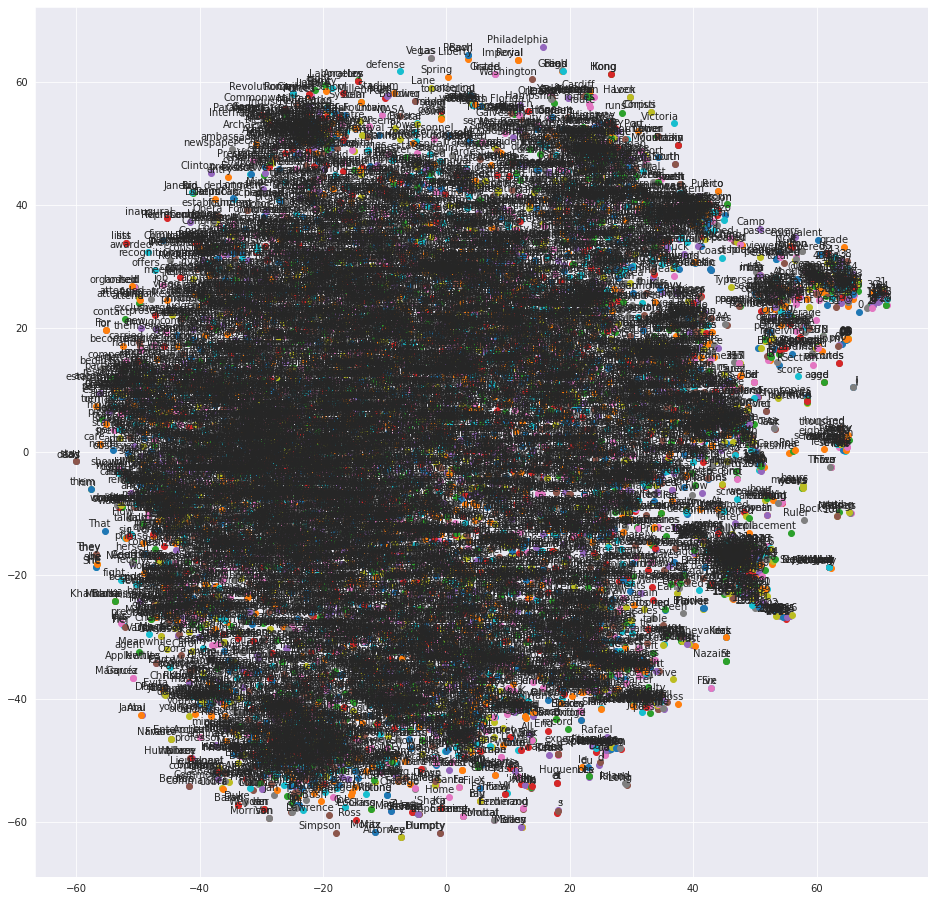

In [24]:
tsne_plot(w2v_model)

## Exploring the model

In [25]:
def getSimilarWords(word,model):
    print(model.wv.most_similar(word))

In [26]:
user_input = input('Enter word to find words similar to it \n')
getSimilarWords(user_input,w2v_model)

Enter word to find words similar to it 
Queen


INFO - 09:02:04: precomputing L2-norms of word weight vectors


[('Charlotte', 0.504953920841217), ('Elizabeth', 0.44463878870010376), ('Gate', 0.4394534230232239), ('Anne', 0.40192240476608276), ('Victoria', 0.3816987872123718), ('queen', 0.378055602312088), ('Cross', 0.3754265308380127), ('Northumberland', 0.3427349627017975), ('Rowley', 0.34242168068885803), ('Mary', 0.340869277715683)]


In [27]:
getSimilarWords('California',w2v_model)

[('Oregon', 0.46133437752723694), ('Florida', 0.44046950340270996), ('Arizona', 0.43154746294021606), ('Portland', 0.4107707440853119), ('Chicago', 0.39628246426582336), ('Los', 0.38749954104423523), ('Nevada', 0.3829416036605835), ('Nebraska', 0.3703961968421936), ('Texas', 0.370078980922699), ('Wyoming', 0.37001681327819824)]


In [28]:
getSimilarWords('music',w2v_model)

[('blues', 0.4978502690792084), ('Madonna', 0.48341435194015503), ('recordings', 0.47097623348236084), ('soundtrack', 0.4647647440433502), ('jazz', 0.4491148591041565), ('gospel', 0.4438426196575165), ('genres', 0.44168782234191895), ('composer', 0.4367544651031494), ('musician', 0.4363584518432617), ('melody', 0.4319060444831848)]


In [29]:
w2v_model.wv.most_similar(positive=["music"])

[('blues', 0.4978502690792084),
 ('Madonna', 0.48341435194015503),
 ('recordings', 0.47097623348236084),
 ('soundtrack', 0.4647647440433502),
 ('jazz', 0.4491148591041565),
 ('gospel', 0.4438426196575165),
 ('genres', 0.44168782234191895),
 ('composer', 0.4367544651031494),
 ('musician', 0.4363584518432617),
 ('melody', 0.4319060444831848)]

In [30]:
w2v_model.wv.most_similar(positive=["movie"])

[('film', 0.5445314049720764),
 ('trailer', 0.5259878635406494),
 ('remake', 0.5150113105773926),
 ('Magadheera', 0.4486180543899536),
 ('cinema', 0.43193519115448),
 ('anime', 0.4312307834625244),
 ('directing', 0.42923325300216675),
 ('films', 0.42741647362709045),
 ('TV', 0.4170152544975281),
 ('Telugu', 0.4161575436592102)]

In [31]:
w2v_model.wv.most_similar(positive=["leaves"])

[('arrives', 0.5404515862464905),
 ('enters', 0.5059434175491333),
 ('eat', 0.4649485945701599),
 ('snake', 0.4577723741531372),
 ('gets', 0.4561440348625183),
 ('flowers', 0.4533047378063202),
 ('realizes', 0.44604215025901794),
 ('shoots', 0.44148123264312744),
 ('finds', 0.4390106499195099),
 ('kills', 0.4270482659339905)]

In [32]:
# Words in vocab

print(w2v_model.wv.vocab)

{'': <gensim.models.keyedvectors.Vocab object at 0x7f9c26f59d50>, '\n': <gensim.models.keyedvectors.Vocab object at 0x7f9c2618e7d0>, '=': <gensim.models.keyedvectors.Vocab object at 0x7f9c2618e610>, 'Valkyria': <gensim.models.keyedvectors.Vocab object at 0x7f9c2618e710>, 'Chronicles': <gensim.models.keyedvectors.Vocab object at 0x7f9c261eb410>, 'III': <gensim.models.keyedvectors.Vocab object at 0x7f9c282728d0>, 'no': <gensim.models.keyedvectors.Vocab object at 0x7f9c263ea910>, '3': <gensim.models.keyedvectors.Vocab object at 0x7f9c263ea6d0>, ':': <gensim.models.keyedvectors.Vocab object at 0x7f9c261ebed0>, '<unk>': <gensim.models.keyedvectors.Vocab object at 0x7f9c261eb9d0>, '(': <gensim.models.keyedvectors.Vocab object at 0x7f9c263ea410>, 'Japanese': <gensim.models.keyedvectors.Vocab object at 0x7f9c263eaf50>, ',': <gensim.models.keyedvectors.Vocab object at 0x7f9c2636fd90>, 'lit': <gensim.models.keyedvectors.Vocab object at 0x7f9c2636f310>, '.': <gensim.models.keyedvectors.Vocab obje

In [33]:
# Similarities

w2v_model.wv.similarity("travel", 'miles')

0.18451636

In [34]:
w2v_model.wv.similarity('boy', 'baby')

0.48270515

In [35]:
# Odd one out

w2v_model.wv.doesnt_match(['sweet', 'team', 'champions'])

/usr/local/lib/python3.7/dist-packages/gensim/models/keyedvectors.py:895: FutureWarning: arrays to stack must be passed as a "sequence" type such as list or tuple. Support for non-sequence iterables such as generators is deprecated as of NumPy 1.16 and will raise an error in the future.
  vectors = vstack(self.word_vec(word, use_norm=True) for word in used_words).astype(REAL)


'sweet'

In [36]:
# Analogy Difference

w2v_model.wv.most_similar(positive=["marriage", "man"], negative=["woman"], topn=3)

[('Anselm', 0.32610583305358887),
 ('consent', 0.29998716711997986),
 ('wishes', 0.29827404022216797)]

## t-SNE visualization

In [37]:
def tsnescatterplot(model, word, list_names):
    """ Plot in seaborn the results from the t-SNE dimensionality reduction algorithm of the vectors of a query word,
    its list of most similar words, and a list of words.
    """
    arrays = np.empty((0, 300), dtype='f')
    word_labels = [word]
    color_list  = ['red']

    # adds the vector of the query word
    arrays = np.append(arrays, model.wv.__getitem__([word]), axis=0)
    
    # gets list of most similar words
    close_words = model.wv.most_similar([word])
    
    # adds the vector for each of the closest words to the array
    for wrd_score in close_words:
        wrd_vector = model.wv.__getitem__([wrd_score[0]])
        word_labels.append(wrd_score[0])
        color_list.append('blue')
        arrays = np.append(arrays, wrd_vector, axis=0)
    
    # adds the vector for each of the words from list_names to the array
    for wrd in list_names:
        wrd_vector = model.wv.__getitem__([wrd])
        word_labels.append(wrd)
        color_list.append('green')
        arrays = np.append(arrays, wrd_vector, axis=0)
        
    # Reduces the dimensionality from 300 to 15 dimensions with PCA
    reduc = PCA(n_components=15).fit_transform(arrays)
    
    # Finds t-SNE coordinates for 2 dimensions
    np.set_printoptions(suppress=True)
    
    Y = TSNE(n_components=2, random_state=0, perplexity=15).fit_transform(reduc)
    
    # Sets everything up to plot
    df = pd.DataFrame({'x': [x for x in Y[:, 0]],
                       'y': [y for y in Y[:, 1]],
                       'words': word_labels,
                       'color': color_list})
    
    fig, _ = plt.subplots()
    fig.set_size_inches(9, 9)
    
    # Basic plot
    p1 = sns.regplot(data=df,
                     x="x",
                     y="y",
                     fit_reg=False,
                     marker="o",
                     scatter_kws={'s': 40,
                                  'facecolors': df['color']
                                 }
                    )
    
    # Adds annotations one by one with a loop
    for line in range(0, df.shape[0]):
         p1.text(df["x"][line],
                 df['y'][line],
                 '  ' + df["words"][line].title(),
                 horizontalalignment='left',
                 verticalalignment='bottom', size='medium',
                 color=df['color'][line],
                 weight='normal'
                ).set_size(15)

    
    plt.xlim(Y[:, 0].min()-50, Y[:, 0].max()+50)
    plt.ylim(Y[:, 1].min()-50, Y[:, 1].max()+50)
            
    plt.title('t-SNE visualization for {}'.format(word.title()))

10 Most similar words vs. 6 Random words:

/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:783: FutureWarning: The default initialization in TSNE will change from 'random' to 'pca' in 1.2.
  FutureWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:793: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  FutureWarning,


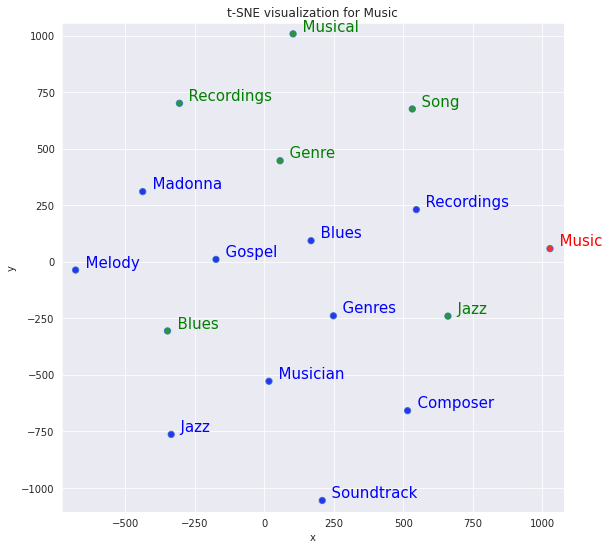

In [38]:
tsnescatterplot(w2v_model, 'music', [ 'musical', 'blues', 'genre', 'recordings', 'jazz', 'song'])

/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:783: FutureWarning: The default initialization in TSNE will change from 'random' to 'pca' in 1.2.
  FutureWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:793: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  FutureWarning,


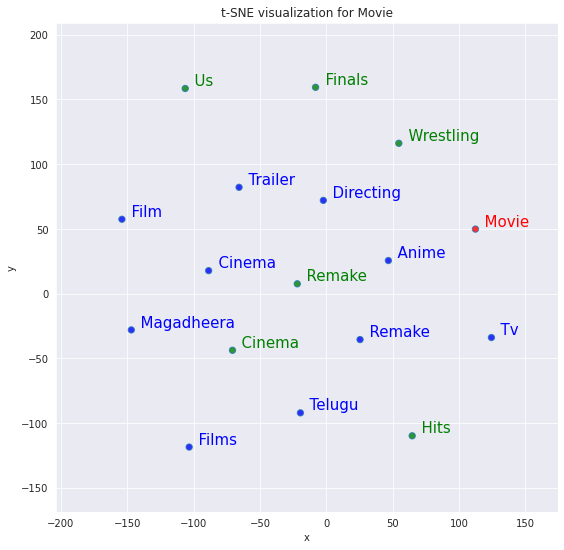

In [39]:
tsnescatterplot(w2v_model, 'movie', [ 'cinema', 'wrestling', 'Finals', 'remake', 'US', 'hits'])

10 Most similar words vs. 10 Most dissimilar words:

/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:783: FutureWarning: The default initialization in TSNE will change from 'random' to 'pca' in 1.2.
  FutureWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:793: FutureWarning: The default learning rate in TSNE will change from 200.0 to 'auto' in 1.2.
  FutureWarning,


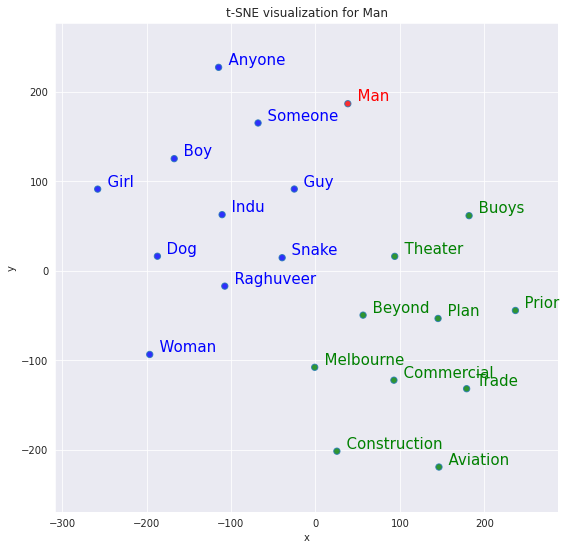

In [40]:
tsnescatterplot(w2v_model, 'man', [i[0] for i in w2v_model.wv.most_similar(negative=["man"])])

## Saving data to tensorboard

In [41]:
print("Vocabulary Size: {0}".format(len(w2v_model.wv.vocab)))

Vocabulary Size: 8836


In [42]:
for i,w in enumerate(w2v_model.wv.vocab):
    print(w)
    if i>4:
        break




=
Valkyria
Chronicles
III


In [43]:
w2v_model["for"].shape

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:1: DeprecationWarning: Call to deprecated `__getitem__` (Method will be removed in 4.0.0, use self.wv.__getitem__() instead).
  """Entry point for launching an IPython kernel.


(300,)

In [44]:
import numpy as np
#Important Parameters
VOCAB_SIZE = len(w2v_model.wv.vocab)
EMBEDDING_DIM = w2v_model["for"].shape[0]
w2v = np.zeros((VOCAB_SIZE, EMBEDDING_DIM))

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:4: DeprecationWarning: Call to deprecated `__getitem__` (Method will be removed in 4.0.0, use self.wv.__getitem__() instead).
  after removing the cwd from sys.path.


In [45]:
tsv_file_path = data_dir + "/logs/word2vec/metadata.tsv"
with open(tsv_file_path,'w+', encoding='utf-8') as file_metadata:
    for i,word in enumerate(w2v_model.wv.index2word[:VOCAB_SIZE]):
        w2v[i] = w2v_model[word]
        file_metadata.write(word+'n')

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:4: DeprecationWarning: Call to deprecated `__getitem__` (Method will be removed in 4.0.0, use self.wv.__getitem__() instead).
  after removing the cwd from sys.path.


In [46]:
import io
# tsv_file_path = data_dir + "/logs/word2vec/metadata.tsv"
out_v = io.open('/content/drive/MyDrive/Colab Notebooks/extra assignment/data_dir/logs/word2vec/vectors.tsv', 'w', encoding='utf-8')
out_m = io.open('/content/drive/MyDrive/Colab Notebooks/extra assignment/data_dir/logs/word2vec/metadata.tsv', 'w', encoding='utf-8')
for i,word in enumerate(w2v_model.wv.index2word[:VOCAB_SIZE]):
    # w2v[i] = w2v_model[word]
    # print(w2v[0],word)
    out_v.write('\t'.join(str(w2v_model[word])) + "\n")
    out_m.write(word + "\n")
out_v.close()
out_m.close()


/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:8: DeprecationWarning: Call to deprecated `__getitem__` (Method will be removed in 4.0.0, use self.wv.__getitem__() instead).
  


In [47]:
# import tensorflow as tf
import tensorflow.compat.v1 as tf
tf.disable_v2_behavior()
# from tensorflow.contrib.tensorboard.plugins import projector
TENSORBOARD_FILES_PATH = data_dir + "/logs/word2vec"

Instructions for updating:
non-resource variables are not supported in the long term


WARNING - 09:02:32: From /usr/local/lib/python3.7/dist-packages/tensorflow/python/compat/v2_compat.py:107: disable_resource_variables (from tensorflow.python.ops.variable_scope) is deprecated and will be removed in a future version.
Instructions for updating:
non-resource variables are not supported in the long term


In [48]:
#Tensorflow Placeholders
X_init = tf.placeholder(tf.float32, shape=(VOCAB_SIZE, EMBEDDING_DIM), name="embedding")
X = tf.Variable(X_init)
#Initializer
init = tf.global_variables_initializer()
#Start Tensorflow Session
sess = tf.Session()
sess.run(init, feed_dict={X_init: w2v})
#Instance of Saver, save the graph.
saver = tf.train.Saver()
writer = tf.summary.FileWriter(TENSORBOARD_FILES_PATH, sess.graph)

In [49]:
#Configure a Tensorflow Projector
config = projector.ProjectorConfig()
embed = config.embeddings.add()
embed.metadata_path = tsv_file_path
#Write a projector_config
projector.visualize_embeddings(writer,config)
#save a checkpoint
saver.save(sess, TENSORBOARD_FILES_PATH+'/model.ckpt', global_step = VOCAB_SIZE)
#close the session
sess.close()

In [50]:
# t = time()

# ! python -m tensorboard.main --logdir="/content/drive/MyDrive/Colab Notebooks/extra assignment/data_dir/logs/word2vec"

# print('Time to train the model: {} mins'.format(round((time() - t) / 60, 2)))

In [51]:
!kill 663

/bin/bash: line 0: kill: (663) - No such process


In [52]:
%reload_ext tensorboard

%tensorboard --logdir "/content/drive/MyDrive/Colab Notebooks/extra assignment/data_dir/logs/word2vec/model.ckpt-8836.data-00000-of-00001"

<IPython.core.display.Javascript object>

## Saving our custom word embedding

In [53]:
from gensim.models import KeyedVectors

In [54]:
model = w2v_model.wv.save_word2vec_format('/content/drive/MyDrive/Colab Notebooks/extra assignment/custom_wikitext_embedding.txt')

INFO - 09:02:38: storing 8836x300 projection weights into /content/drive/MyDrive/Colab Notebooks/extra assignment/custom_wikitext_embedding.txt


In [55]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
